# 02 - Modeling experiments

**Issues:** #7 (preprocessing pipeline), #8 (baseline) and #9 (feature engineering). Model comparison, class imbalance and tuning (#10 to #13) will be added below as they are done.

**Rules:** only the training and validation sets are used here; the test set stays untouched until the final evaluation (#20). Reusable code lives in `src/`; this notebook imports it.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.data.clean import load_clean_split
from src.features.preprocessing import FEATURES, build_preprocessor, get_xy
from src.features.engineering import ENGINEERED_FEATURES, SELECTED_DROP, SELECTED_ENGINEERED
from src.models.baseline import build_baseline
from src.models.cv import CV_METRICS, N_SPLITS, RANDOM_STATE, cross_validate_model, paired_gain, summarize
from src.models.evaluate import classification_metrics, comparison_to_markdown, update_comparison_table

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

sns.set_theme(style="whitegrid")
REPORTS = ROOT / "reports"

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

## 1. Preprocessing pipeline (issue #7)

In [2]:
train = load_clean_split("train")   # cleaning rule from src/data/clean.py already applied
val = load_clean_split("val")
X_train, y_train = get_xy(train)
X_val, y_val = get_xy(val)
print(f"train: {X_train.shape} | validation: {X_val.shape}")
print(f"features used ({len(FEATURES)}): {FEATURES}")

train: (19443, 11) | validation: (6482, 11)
features used (11): ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'loan_grade', 'cb_person_default_on_file', 'person_home_ownership', 'loan_intent']


### Tree-based variant
Raw numeric scales are kept (trees are scale-invariant). The pipeline is **fitted on the training set only**, then applied to validation.

In [3]:
tree_pipe = build_preprocessor("tree")
Xt_train = tree_pipe.fit_transform(X_train)
Xt_val = tree_pipe.transform(X_val)

print(f"output shape: train {Xt_train.shape} | validation {Xt_val.shape}")
print(f"missing values after transform: train {int(Xt_train.isna().sum().sum())} | validation {int(Xt_val.isna().sum().sum())}")
print(f"same columns in train and validation: {list(Xt_train.columns) == list(Xt_val.columns)}")
print()
print(list(Xt_train.columns))

output shape: train (19443, 20) | validation (6482, 20)
missing values after transform: train 0 | validation 0
same columns in train and validation: True

['person_income', 'person_emp_length', 'person_emp_length_missing', 'person_age', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'loan_grade', 'cb_person_default_on_file', 'person_home_ownership_MORTGAGE', 'person_home_ownership_OTHER', 'person_home_ownership_OWN', 'person_home_ownership_RENT', 'loan_intent_DEBTCONSOLIDATION', 'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL', 'loan_intent_PERSONAL', 'loan_intent_VENTURE']


### What the pipeline learned (from the training set)

In [4]:
imputer = tree_pipe.named_steps["rate_imputer"]
emp_median = tree_pipe.named_steps["columns"].named_transformers_["emp_length"].named_steps["impute"].statistics_[0]

learned = pd.Series(imputer.group_medians_, name="median loan_int_rate").round(2).to_frame()
display(learned)
print(f"global median loan_int_rate (fallback for unseen grades): {imputer.global_median_:.2f}")
print(f"median person_emp_length: {emp_median:.1f}")

# The learned medians must equal a direct computation on the training set alone.
direct = X_train.groupby("loan_grade")["loan_int_rate"].median()
assert all(abs(direct[g] - m) < 1e-12 for g, m in imputer.group_medians_.items())
print("Check passed: grade medians come from the training set only.")

,median loan_int_rate
A,7.49
B,10.99
C,13.48
D,15.31
E,16.77
F,18.43
G,20.11


global median loan_int_rate (fallback for unseen grades): 10.99
median person_emp_length: 4.0
Check passed: grade medians come from the training set only.


### Missing-value indicator for `person_emp_length`

In [5]:
for name, raw, out in (("train", X_train, Xt_train), ("validation", X_val, Xt_val)):
    print(f"{name:10s} raw missing share = {raw['person_emp_length'].isna().mean():.4f} | indicator share = {out['person_emp_length_missing'].mean():.4f}")

train      raw missing share = 0.0278 | indicator share = 0.0278
validation raw missing share = 0.0287 | indicator share = 0.0287


### Linear variant
`person_income` goes through `log1p`, and all numeric features are standardized. Means and standard deviations are those of the **training** set, so validation values are close to, but not exactly, 0 and 1.

In [6]:
lin_pipe = build_preprocessor("linear")
Xl_train = lin_pipe.fit_transform(X_train)
Xl_val = lin_pipe.transform(X_val)

numeric = ["person_age", "person_income", "person_emp_length", "loan_amnt", "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length"]
summary = pd.concat(
    {"train": Xl_train[numeric].agg(["mean", "std"]).T, "validation": Xl_val[numeric].agg(["mean", "std"]).T},
    axis=1,
).round(3)
display(summary)

train      validation       
                            mean  std       mean    std
person_age                   0.0  1.0     -0.010  1.005
person_income                0.0  1.0     -0.014  0.994
person_emp_length           -0.0  1.0     -0.014  0.987
loan_amnt                   -0.0  1.0      0.001  0.999
loan_int_rate                0.0  1.0     -0.001  1.006
loan_percent_income         -0.0  1.0      0.015  0.996
cb_person_cred_hist_length  -0.0  1.0      0.002  0.994

### Summary

- The pipeline has **20 output columns** (7 numeric, 1 missing-value indicator, 2 ordinal, 10 one-hot) and leaves no missing value.
- Imputation medians (interest rate by grade, employment length) are learned on the training set and reused unchanged on validation; a direct computation confirms it.
- Two variants share the same code: `tree` (raw scales) and `linear` (log income + standardization).
- Unknown grades raise an error, unknown home ownership or loan intent values are encoded as all zeros (see `tests/test_preprocessing.py`).
- The fitted pipeline can be saved with `save_preprocessor` and reloaded by the API.

## 2. Baseline: logistic regression (issue #8)

The reference every later model must beat: the `linear` preprocessing variant followed by a plain logistic regression (default regularization, no class weights). Class imbalance is handled in issue #11, not here.

Metrics are computed on the **validation set**. ROC AUC, PR AUC, KS and Brier score do not depend on a threshold. Recall and precision are shown at the default threshold of 0.5 only as a reference: the cost-optimal threshold is chosen in issue #16.

In [7]:
prevalence = y_train.mean()
print(f"default rate: train {prevalence:.4f} | validation {y_val.mean():.4f}")

# Reference without any model: the same probability for everyone (the training default rate).
dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)
dummy_scores = dummy.predict_proba(X_val)[:, 1]
dummy_metrics = classification_metrics(y_val, dummy_scores)

baseline = build_baseline().fit(X_train, y_train)
val_scores = baseline.predict_proba(X_val)[:, 1]
base_metrics = classification_metrics(y_val, val_scores)

metric_cols = ["roc_auc", "pr_auc", "ks", "brier", "recall", "precision"]
results = pd.DataFrame({"constant prior (no model)": dummy_metrics, "logistic regression": base_metrics}).T[metric_cols]
display(results.round(4))

default rate: train 0.2187 | validation 0.2188


,roc_auc,pr_auc,ks,brier,recall,precision
constant prior (no model),0.5000,0.2188,0.0000,0.1709,0.0000,0.0000
logistic regression,0.8767,0.7230,0.6107,0.1036,0.5437,0.7406


In [8]:
print(f"Confusion matrix at threshold 0.5 (validation, {len(y_val)} rows)")
cm = pd.DataFrame(
    [[base_metrics["tn"], base_metrics["fp"]], [base_metrics["fn"], base_metrics["tp"]]],
    index=["actual: no default", "actual: default"],
    columns=["predicted: no default", "predicted: default"],
)
display(cm)

Confusion matrix at threshold 0.5 (validation, 6482 rows)


,predicted: no default,predicted: default
actual: no default,4794,270
actual: default,647,771


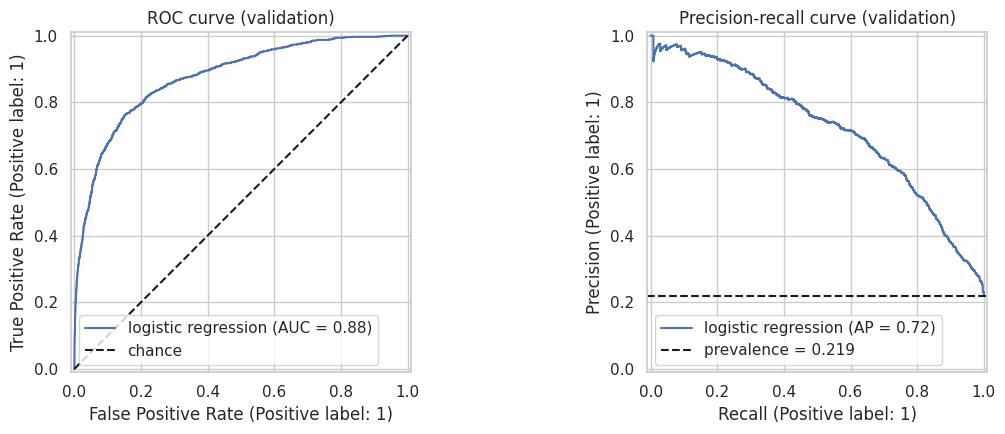

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
RocCurveDisplay.from_predictions(y_val, val_scores, name="logistic regression", ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", label="chance")
axes[0].set_title("ROC curve (validation)")
axes[0].legend()
PrecisionRecallDisplay.from_predictions(y_val, val_scores, name="logistic regression", ax=axes[1])
axes[1].axhline(y_val.mean(), color="k", linestyle="--", label=f"prevalence = {y_val.mean():.3f}")
axes[1].set_title("Precision-recall curve (validation)")
axes[1].legend()
fig.tight_layout()
fig.savefig(REPORTS / "figures" / "baseline_roc_pr.png", dpi=130, bbox_inches="tight")
plt.show()

In [10]:
names = baseline.named_steps["preprocess"].get_feature_names_out()
coefs = pd.Series(baseline.named_steps["model"].coef_[0], index=names).sort_values()
print("Largest negative and positive coefficients. Read the sign only: binary/ordinal columns and standardized numeric columns are not on the same scale.")
display(pd.concat([coefs.head(5), coefs.tail(5)]).round(3).to_frame("coefficient"))

Largest negative and positive coefficients. Read the sign only: binary/ordinal columns and standardized numeric columns are not on the same scale.


,coefficient
person_home_ownership_OWN,-2.104
loan_intent_VENTURE,-1.048
loan_intent_EDUCATION,-0.791
person_income,-0.611
loan_intent_PERSONAL,-0.582
loan_intent_HOMEIMPROVEMENT,0.137
person_home_ownership_RENT,0.209
person_emp_length_missing,0.537
loan_percent_income,0.821
loan_grade,1.088


In [11]:
table = update_comparison_table(
    REPORTS / "model_comparison.csv", "constant prior (no model)", dummy_metrics,
    notes="same probability for everyone",
)
table = update_comparison_table(
    REPORTS / "model_comparison.csv", "logistic regression (baseline)", base_metrics,
    notes="linear preprocessing, default C=1, no class weights",
)
display(table)
print(comparison_to_markdown(table))

,model,split,roc_auc,pr_auc,ks,brier,recall,precision,threshold,notes
0,logistic + loan_to_income (replaces loan_perce...,validation,0.8779,0.7261,0.6089,0.1029,0.5501,0.7436,0.5,issue 9: recomputed ratio replaces the provide...
1,constant prior (no model),validation,0.5000,0.2188,0.0000,0.1709,0.0000,0.0000,0.5,same probability for everyone
2,logistic regression (baseline),validation,0.8767,0.7230,0.6107,0.1036,0.5437,0.7406,0.5,"linear preprocessing, default C=1, no class we..."


| Model | ROC AUC | PR AUC | KS | Brier | Recall | Precision |
|---|---|---|---|---|---|---|
| logistic + loan_to_income (replaces loan_percent_income) | 0.878 | 0.726 | 0.609 | 0.103 | 0.550 | 0.744 |
| constant prior (no model) | 0.500 | 0.219 | 0.000 | 0.171 | 0.000 | 0.000 |
| logistic regression (baseline) | 0.877 | 0.723 | 0.611 | 0.104 | 0.544 | 0.741 |


### Baseline summary (validation set, single split)

- **Ranking quality:** ROC AUC 0.877, PR AUC 0.723 (versus 0.219 for a constant prediction, about 3.3 times higher) and KS 0.611.
- **Probability quality:** Brier score 0.104, versus 0.171 for the constant prediction.
- **At the default threshold of 0.5:** 771 of the 1,418 defaults are caught (recall 54.4%) and 771 of the 1,041 flagged customers really default (precision 74.1%). 647 defaults are missed and 270 good customers are refused.
- **Hypothesis for issue #16:** since a missed default is assumed to cost about 5 times more than a refused good customer, a threshold below 0.5 will probably be cheaper. This is not quantified yet.
- **Signs of the coefficients** match the EDA: higher grade, higher loan-to-income and a missing employment length push the default probability up; higher income and home ownership push it down.
- **Limits:** one validation split and no confidence interval, so small differences between models must be confirmed with cross-validation (issue #10).

**To beat:** PR AUC 0.723, KS 0.611, ROC AUC 0.877.

## 3. Feature engineering (issue #9)

### Protocol (fixed before looking at any result)

- **Data:** the cleaned **training set only**, with 5-fold stratified cross-validation (same folds for every candidate, seed 42). Validation and test are not used to choose features.
- **Two model families**, because a gain for a linear model can vanish for trees: the logistic regression of the baseline, and a gradient boosting model (`HistGradientBoostingClassifier`, default settings, as a quick tree-based reference; the real model comparison is issue #10).
- **Candidates**, each added alone: `loan_to_income` (recomputed ratio), `rate_vs_grade_median` (rate minus the median rate of its grade), `cred_hist_to_age` (credit history length over age), `high_burden` (loan-to-income above 0.25, a threshold taken from the EDA). Also tested: `loan_to_income` **replacing** `loan_percent_income`, and all four together.
- **Metric:** PR AUC (KS is shown as a check). The gain is the paired fold-by-fold difference with the baseline.
- **Selection rule:** keep a candidate if its mean PR AUC gain is larger than the standard deviation of the paired differences **in at least one family**, and is not negative in **either** family.

In [12]:
X_tr, y_tr = X_train, y_train          # cleaned training set; validation is not touched in this section

def tree_model(**kw):
    return Pipeline([
        ("preprocess", build_preprocessor("tree", **kw)),
        ("model", HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
    ])

configs = {
    "baseline": dict(engineered=(), drop=()),
    "+ loan_to_income": dict(engineered=("loan_to_income",), drop=()),
    "loan_to_income replaces loan_percent_income": dict(engineered=("loan_to_income",), drop=("loan_percent_income",)),
    "+ rate_vs_grade_median": dict(engineered=("rate_vs_grade_median",), drop=()),
    "+ cred_hist_to_age": dict(engineered=("cred_hist_to_age",), drop=()),
    "+ high_burden": dict(engineered=("high_burden",), drop=()),
    "+ all four": dict(engineered=tuple(ENGINEERED_FEATURES), drop=()),
}
makers = {"logistic": lambda c: build_baseline(**c), "gradient boosting": lambda c: tree_model(**c)}

cv = {(fam, name): cross_validate_model(make(cfg), X_tr, y_tr) for fam, make in makers.items() for name, cfg in configs.items()}

for fam in makers:
    s = summarize(cv[(fam, "baseline")])
    print(f"{fam:18s} baseline (5-fold CV on train): PR AUC {s.loc['pr_auc','mean']:.4f} +/- {s.loc['pr_auc','std']:.4f} | KS {s.loc['ks','mean']:.4f} | ROC AUC {s.loc['roc_auc','mean']:.4f}")

logistic           baseline (5-fold CV on train): PR AUC 0.7060 +/- 0.0181 | KS 0.5809 | ROC AUC 0.8662
gradient boosting  baseline (5-fold CV on train): PR AUC 0.8918 +/- 0.0026 | KS 0.7381 | ROC AUC 0.9391


In [13]:
rows = []
for name in list(configs)[1:]:
    row = {"candidate": name}
    for fam in makers:
        g = paired_gain(cv[(fam, "baseline")], cv[(fam, name)], "pr_auc")
        k = paired_gain(cv[(fam, "baseline")], cv[(fam, name)], "ks")
        row.update({
            f"{fam}: dPR AUC": g["mean_gain"], f"{fam}: sd": g["std_gain"], f"{fam}: folds+": f"{g['folds_improved']}/{g['n_folds']}",
            f"{fam}: dKS": k["mean_gain"],
        })
    rows.append(row)
gains = pd.DataFrame(rows).set_index("candidate")
display(gains.round(4))

def passes_rule(name):
    g = {fam: paired_gain(cv[(fam, "baseline")], cv[(fam, name)], "pr_auc") for fam in makers}
    beats_noise = any(v["mean_gain"] > v["std_gain"] for v in g.values())
    never_harmful = all(v["mean_gain"] >= 0 for v in g.values())
    return beats_noise and never_harmful

passing = [n for n in list(configs)[1:] if passes_rule(n)]
print("Candidates passing the rule:", passing)

,logistic: dPR AUC,logistic: sd,logistic: folds+,logistic: dKS,gradient boosting: dPR AUC,gradient boosting: sd,gradient boosting: folds+,gradient boosting: dKS
candidate,,,,,,,,
+ loan_to_income,0.0151,0.0036,5/5,0.0086,0.0005,0.0024,3/5,0.0003
loan_to_income replaces loan_percent_income,0.0030,0.0007,5/5,0.0023,0.0006,0.0021,3/5,-0.0013
+ rate_vs_grade_median,0.0047,0.0040,5/5,0.0127,-0.0007,0.0016,2/5,-0.0040
+ cred_hist_to_age,0.0001,0.0006,3/5,0.0007,-0.0000,0.0017,3/5,-0.0020
+ high_burden,0.0022,0.0034,4/5,0.0076,0.0000,0.0000,0/5,0.0000
+ all four,0.0225,0.0084,5/5,0.0329,-0.0023,0.0035,2/5,-0.0037


Candidates passing the rule: ['+ loan_to_income', 'loan_to_income replaces loan_percent_income']


### The surprising gain: a leakage check

`loan_to_income` helps the logistic regression a lot when it is **added** (+0.015 PR AUC, better on all 5 folds) but much less when it **replaces** `loan_percent_income`. If it were just a finer version of the same ratio, both variants should give a similar gain. So the information must lie in the **difference** between the two ratios. Let us look at the rows where they disagree (training set only).

In [14]:
recomputed = X_tr["loan_amnt"] / X_tr["person_income"]
gap = X_tr["loan_percent_income"] - recomputed.round(2)
mismatch = gap.abs() > 0.011

print(f"rows where the provided ratio differs from the recomputed one: {int(mismatch.sum())} of {len(X_tr)} ({mismatch.mean():.2%})")
print(f"default rate: mismatched rows {y_tr[mismatch].mean():.3f} (n={int(mismatch.sum())}) | consistent rows {y_tr[~mismatch].mean():.3f}")
print(f"provided ratio lower than recomputed on {int((gap[mismatch] < 0).sum())} of {int(mismatch.sum())} mismatched rows")

rows where the provided ratio differs from the recomputed one: 211 of 19443 (1.09%)
default rate: mismatched rows 1.000 (n=211) | consistent rows 0.210
provided ratio lower than recomputed on 211 of 211 mismatched rows


In [15]:
def cv_with_mismatch_flag(X, y):
    flag = ((X["loan_percent_income"] - (X["loan_amnt"] / X["person_income"]).round(2)).abs() > 0.011).astype(float)
    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    out = []
    for fold, (tr, va) in enumerate(skf.split(X, y)):
        prep = build_preprocessor("linear")
        A = prep.fit_transform(X.iloc[tr]).assign(ratio_mismatch=flag.iloc[tr].to_numpy())
        B = prep.transform(X.iloc[va]).assign(ratio_mismatch=flag.iloc[va].to_numpy())
        model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(A, y.iloc[tr])
        m = classification_metrics(y.iloc[va], model.predict_proba(B)[:, 1])
        out.append({"fold": fold, **{k: m[k] for k in CV_METRICS}})
    return pd.DataFrame(out)

flag_cv = cv_with_mismatch_flag(X_tr, y_tr)
g_flag = paired_gain(cv[("logistic", "baseline")], flag_cv, "pr_auc")
g_add = paired_gain(cv[("logistic", "baseline")], cv[("logistic", "+ loan_to_income")], "pr_auc")
g_rep = paired_gain(cv[("logistic", "baseline")], cv[("logistic", "loan_to_income replaces loan_percent_income")], "pr_auc")
print("Logistic regression, PR AUC gain over the baseline (5-fold CV on train):")
print(f"  + loan_to_income (added)           : {g_add['mean_gain']:+.4f}  ({g_add['folds_improved']}/5 folds)")
print(f"  + a bare 'ratios disagree' flag    : {g_flag['mean_gain']:+.4f}  ({g_flag['folds_improved']}/5 folds)")
print(f"  loan_to_income replaces the ratio  : {g_rep['mean_gain']:+.4f}  ({g_rep['folds_improved']}/5 folds)")

Logistic regression, PR AUC gain over the baseline (5-fold CV on train):
  + loan_to_income (added)           : +0.0151  (5/5 folds)
  + a bare 'ratios disagree' flag    : +0.0264  (5/5 folds)
  loan_to_income replaces the ratio  : +0.0030  (5/5 folds)


### Decision

The mismatch flag alone reproduces the whole gain of the added ratio, and every mismatched row is a default. This is a **construction artifact of the dataset (target leakage)**, not a signal available at decision time: a real loan application has one consistent ratio, so the mismatch would never occur in production.

- **Rejected:** adding `loan_to_income` next to `loan_percent_income`. The rule alone would have kept it, so a leakage check is added to the protocol (disclosed here because the gain was surprising and looked at after the fact).
- **Kept:** `loan_to_income` **replacing** `loan_percent_income`. It removes the artifact from the model inputs, passes the rule in both families and simplifies the API: only `loan_amnt` and `person_income` are needed.
- **Rejected:** `rate_vs_grade_median` (negative for gradient boosting), `cred_hist_to_age` (no gain beyond noise), `high_burden` (no gain beyond noise for the logistic regression, strictly redundant for trees), and "all four" (negative for gradient boosting).
- **Do not delete the mismatched rows:** they are all defaults, so removing them would erase part of the positive class.

In [16]:
final_engineered = ("loan_to_income",)
final_drop = ("loan_percent_income",)
assert final_engineered == tuple(SELECTED_ENGINEERED) and final_drop == tuple(SELECTED_DROP), "update src/features/engineering.py"
print("Selected:", final_engineered, "replacing", final_drop)

Selected: ('loan_to_income',) replacing ('loan_percent_income',)


### Validation check of the selected set

Evaluated **once** on the validation set, with the same logistic regression as the baseline.

In [17]:
selected = build_baseline(engineered=final_engineered, drop=final_drop).fit(X_train, y_train)
sel_scores = selected.predict_proba(X_val)[:, 1]
sel_metrics = classification_metrics(y_val, sel_scores)

compare = pd.DataFrame({
    "logistic regression (baseline)": base_metrics,
    "logistic + loan_to_income (replaces loan_percent_income)": sel_metrics,
}).T[metric_cols]
display(compare.round(4))

table = update_comparison_table(
    REPORTS / "model_comparison.csv", "logistic + loan_to_income (replaces loan_percent_income)", sel_metrics,
    notes="issue 9: recomputed ratio replaces the provided one (removes the leakage artifact)",
)
print(comparison_to_markdown(table))

,roc_auc,pr_auc,ks,brier,recall,precision
logistic regression (baseline),0.8767,0.7230,0.6107,0.1036,0.5437,0.7406
logistic + loan_to_income (replaces loan_percent_income),0.8779,0.7261,0.6089,0.1029,0.5501,0.7436


| Model | ROC AUC | PR AUC | KS | Brier | Recall | Precision |
|---|---|---|---|---|---|---|
| constant prior (no model) | 0.500 | 0.219 | 0.000 | 0.171 | 0.000 | 0.000 |
| logistic regression (baseline) | 0.877 | 0.723 | 0.611 | 0.104 | 0.544 | 0.741 |
| logistic + loan_to_income (replaces loan_percent_income) | 0.878 | 0.726 | 0.609 | 0.103 | 0.550 | 0.744 |


### Feature engineering summary (training-set cross-validation, validation check)

- **Cross-validated reference (train, 5 folds):** logistic regression PR AUC 0.706 +/- 0.018, gradient boosting 0.892 +/- 0.003. The gap between the two families is large, which is worth watching in issues #10 and #19 for any further artifact like the one found below.
- **Selected:** `loan_to_income` replaces `loan_percent_income` (PR AUC +0.003 for the logistic regression on 5 of 5 folds, +0.0006 for gradient boosting, within noise). Gains are small by design: the point is robustness, not score.
- **Rejected:** `rate_vs_grade_median`, `cred_hist_to_age`, `high_burden` and the "all four" set (no gain beyond noise or negative for gradient boosting).
- **Data artifact found:** in the training set, the provided `loan_percent_income` differs from `loan_amnt / person_income` on 211 rows (1.09%), all of them defaults and always with a lower provided value. Adding the recomputed ratio next to the provided one would have let the model read this leak (+0.015 PR AUC), which would not exist in production.
- **Validation set, logistic regression:** ROC AUC 0.878 versus 0.877, PR AUC 0.726 versus 0.723, Brier 0.103 versus 0.104, recall 0.550 versus 0.544; KS 0.609 versus 0.611. One split, no confidence interval: the differences are small and not significant on their own.
- **API consequence:** `loan_percent_income` is no longer a model input, so the API only needs `loan_amnt` and `person_income`.